In [1]:
print("Retail Sales Data Cleaning & Analysis")

Retail Sales Data Cleaning & Analysis


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data = {
    'order_id': [
        101, 102, 103, 104, 105,
        106, 107, 108, 109, 110,
        111, 112, 113, 114, 115,
        103, 117
    ],

    'date': [
        '2026-01-05', '2026/01/06', '2026-01-07',
        '2026-01-08', '2026-01-09', '2026-01-10',
        '2026-01-11', '2026-01-12', '2026-01-13',
        '2026-01-14', '2026-01-15', '2026-01-16',
        '2026-01-17', '2026-01-18', 'invalid',
        '2026-01-07', '2026-01-20'
    ],

    'product': [
        'Laptop', ' Mouse ', 'Keyboard', 'Laptop', 'Monitor',
        'mouse', 'Keyboard ', 'Laptop', 'Monitor', 'Mouse',
        'Laptop', 'Keyboard', 'Monitor', 'Laptop', 'Mouse',
        'Keyboard', 'Monitor'
    ],

    'category': [
        'Electronics', 'Accessories', 'accessories',
        'Electronics', 'Electronics', 'Accessories',
        'Accessories', 'Electronics', 'electronics',
        'Accessories', 'Electronics', 'Accessories',
        'Electronics', 'Electronics', 'Accessories',
        'accessories', 'Electronics'
    ],

    'city': [
        'Jaipur', 'Delhi', 'Jaipur', 'Mumbai', 'Delhi',
        ' Jaipur ', 'Mumbai', 'Delhi', 'Jaipur', 'Mumbai',
        'Delhi', 'Jaipur', 'Mumbai', 'Delhi', 'Jaipur',
        'Jaipur', 'Delhi'
    ],

    'quantity': [
        2, 5, 3, np.nan, 2, 4, 0, 1, 3,
        2, -1, 5, 2, 1, 4, 3, 2
    ],

    'price': [
        50000, 500, 800, 50000, 12000,
        500, np.nan, 50000, 12000, 500,
        50000, 800, 12000, 50000, 500,
        800, 12000
    ]
}

df = pd.DataFrame(data)

print(df)

    order_id        date    product     category      city  quantity    price
0        101  2026-01-05     Laptop  Electronics    Jaipur       2.0  50000.0
1        102  2026/01/06     Mouse   Accessories     Delhi       5.0    500.0
2        103  2026-01-07   Keyboard  accessories    Jaipur       3.0    800.0
3        104  2026-01-08     Laptop  Electronics    Mumbai       NaN  50000.0
4        105  2026-01-09    Monitor  Electronics     Delhi       2.0  12000.0
5        106  2026-01-10      mouse  Accessories   Jaipur        4.0    500.0
6        107  2026-01-11  Keyboard   Accessories    Mumbai       0.0      NaN
7        108  2026-01-12     Laptop  Electronics     Delhi       1.0  50000.0
8        109  2026-01-13    Monitor  electronics    Jaipur       3.0  12000.0
9        110  2026-01-14      Mouse  Accessories    Mumbai       2.0    500.0
10       111  2026-01-15     Laptop  Electronics     Delhi      -1.0  50000.0
11       112  2026-01-16   Keyboard  Accessories    Jaipur      

In [4]:
# Clean the data using Pandas
print(df.head())
print(df.tail())
print(df.shape)
print(df.columns)
print(df.info())
print(df.describe(include='all'))

   order_id        date   product     category    city  quantity    price
0       101  2026-01-05    Laptop  Electronics  Jaipur       2.0  50000.0
1       102  2026/01/06    Mouse   Accessories   Delhi       5.0    500.0
2       103  2026-01-07  Keyboard  accessories  Jaipur       3.0    800.0
3       104  2026-01-08    Laptop  Electronics  Mumbai       NaN  50000.0
4       105  2026-01-09   Monitor  Electronics   Delhi       2.0  12000.0
    order_id        date   product     category    city  quantity    price
12       113  2026-01-17   Monitor  Electronics  Mumbai       2.0  12000.0
13       114  2026-01-18    Laptop  Electronics   Delhi       1.0  50000.0
14       115     invalid     Mouse  Accessories  Jaipur       4.0    500.0
15       103  2026-01-07  Keyboard  accessories  Jaipur       3.0    800.0
16       117  2026-01-20   Monitor  Electronics   Delhi       2.0  12000.0
(17, 7)
Index(['order_id', 'date', 'product', 'category', 'city', 'quantity', 'price'], dtype='object')
<c

In [7]:
# Find missing values
print(df.isnull().sum())
print(df.isnull().sum().sum())

order_id    0
date        0
product     0
category    0
city        0
quantity    1
price       1
dtype: int64
2


In [9]:
# Find the percentage of missing values in each column:
missing_percent = df.isnull().mean() * 100

print(missing_percent)

order_id    0.000000
date        0.000000
product     0.000000
category    0.000000
city        0.000000
quantity    5.882353
price       5.882353
dtype: float64


In [10]:
# Remove duplicate records
print(df.duplicated().sum())

1


In [13]:
df = df.drop_duplicates()
print(df[df.duplicated(subset='order_id', keep=False)])

Empty DataFrame
Columns: [order_id, date, product, category, city, quantity, price]
Index: []


In [14]:
df = df.drop_duplicates(
    subset='order_id',
    keep='first'
)

In [15]:
# Clean text columns
df['product'] = (
    df['product']
    .str.strip()
    .str.title()
)

df['category'] = (
    df['category']
    .str.strip()
    .str.title()
)

df['city'] = (
    df['city']
    .str.strip()
    .str.title()
)

print(df[['product', 'category', 'city']])

     product     category    city
0     Laptop  Electronics  Jaipur
1      Mouse  Accessories   Delhi
2   Keyboard  Accessories  Jaipur
3     Laptop  Electronics  Mumbai
4    Monitor  Electronics   Delhi
5      Mouse  Accessories  Jaipur
6   Keyboard  Accessories  Mumbai
7     Laptop  Electronics   Delhi
8    Monitor  Electronics  Jaipur
9      Mouse  Accessories  Mumbai
10    Laptop  Electronics   Delhi
11  Keyboard  Accessories  Jaipur
12   Monitor  Electronics  Mumbai
13    Laptop  Electronics   Delhi
14     Mouse  Accessories  Jaipur
16   Monitor  Electronics   Delhi


In [16]:
# Fix data types
df['date'] = pd.to_datetime(
    df['date'],
    errors='coerce'
)

print(df['date'])

0    2026-01-05
1           NaT
2    2026-01-07
3    2026-01-08
4    2026-01-09
5    2026-01-10
6    2026-01-11
7    2026-01-12
8    2026-01-13
9    2026-01-14
10   2026-01-15
11   2026-01-16
12   2026-01-17
13   2026-01-18
14          NaT
16   2026-01-20
Name: date, dtype: datetime64[ns]


In [17]:
# Convert quantity and price to numeric values if needed:
df['quantity'] = pd.to_numeric(
    df['quantity'],
    errors='coerce'
)

df['price'] = pd.to_numeric(
    df['price'],
    errors='coerce'
)

In [18]:
# Handle missing values
df = df.dropna(subset=['date'])

In [19]:
df['quantity'] = df['quantity'].fillna(
    df['quantity'].median()
)

df['price'] = df['price'].fillna(
    df.groupby('product')['price']
      .transform('median')
)

In [20]:
# Handle invalid values
df = df[
    (df['quantity'] > 0) &
    (df['price'] > 0)
].copy()

In [21]:
# Create new columns
df['total_sales'] = (
    df['quantity'] * df['price']
)

In [22]:
# Extract the month and weekday from the order date:
df['month'] = df['date'].dt.month_name()

df['day'] = df['date'].dt.day_name()

In [23]:
# Categorize orders using NumPy:
df['sales_type'] = np.where(
    df['total_sales'] >= 20000,
    'High Sales',
    'Low Sales'
)

In [24]:
# Verify the cleaned dataset
print(df.head(10))
print(df.info())
print(df.isnull().sum())
print(df.duplicated().sum())

    order_id       date   product     category    city  quantity    price  \
0        101 2026-01-05    Laptop  Electronics  Jaipur       2.0  50000.0   
2        103 2026-01-07  Keyboard  Accessories  Jaipur       3.0    800.0   
3        104 2026-01-08    Laptop  Electronics  Mumbai       2.0  50000.0   
4        105 2026-01-09   Monitor  Electronics   Delhi       2.0  12000.0   
5        106 2026-01-10     Mouse  Accessories  Jaipur       4.0    500.0   
7        108 2026-01-12    Laptop  Electronics   Delhi       1.0  50000.0   
8        109 2026-01-13   Monitor  Electronics  Jaipur       3.0  12000.0   
9        110 2026-01-14     Mouse  Accessories  Mumbai       2.0    500.0   
11       112 2026-01-16  Keyboard  Accessories  Jaipur       5.0    800.0   
12       113 2026-01-17   Monitor  Electronics  Mumbai       2.0  12000.0   

    total_sales    month        day  sales_type  
0      100000.0  January     Monday  High Sales  
2        2400.0  January  Wednesday   Low Sales  
3 

In [25]:
# Save the cleaned data to a CSV file:
df.to_csv('cleaned_retail_sales.csv', index=False)

In [26]:
# Analyze the cleaned data


In [28]:
# A. Which products generate the most revenue?
product_sales = df.groupby('product')['total_sales'].sum()

print(product_sales.sort_values(ascending=False))

product
Laptop      300000.0
Monitor     108000.0
Keyboard      6400.0
Mouse         3000.0
Name: total_sales, dtype: float64


In [29]:
# B. Which city has the highest sales?
city_sales = df.groupby('city')['total_sales'].sum()

print(city_sales.sort_values(ascending=False))

city
Delhi     148000.0
Jaipur    144400.0
Mumbai    125000.0
Name: total_sales, dtype: float64


In [30]:
# C. What is the average product price?
print(df.groupby('product')['price'].mean())

product
Keyboard      800.0
Laptop      50000.0
Monitor     12000.0
Mouse         500.0
Name: price, dtype: float64


In [31]:
# D. Which orders have high sales?
high_sales = df.loc[
    df['sales_type'] == 'High Sales',
    ['order_id', 'product', 'total_sales']
]

print(high_sales)

    order_id  product  total_sales
0        101   Laptop     100000.0
3        104   Laptop     100000.0
4        105  Monitor      24000.0
7        108   Laptop      50000.0
8        109  Monitor      36000.0
12       113  Monitor      24000.0
13       114   Laptop      50000.0
16       117  Monitor      24000.0


In [32]:
# E. What are the sales totals by category?
category_sales = df.groupby('category')['total_sales'].sum()

print(category_sales)

category
Accessories      9400.0
Electronics    408000.0
Name: total_sales, dtype: float64


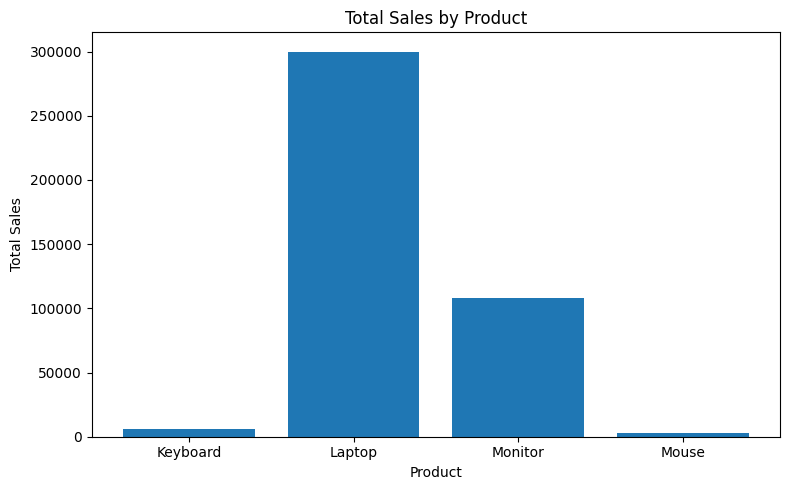

In [33]:
# 6. Create visualizations
# Chart 1: Product-wise sales using Matplotlib
product_sales = df.groupby('product')['total_sales'].sum()

plt.figure(figsize=(8, 5))

plt.bar(product_sales.index, product_sales.values)

plt.title('Total Sales by Product')
plt.xlabel('Product')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.show()

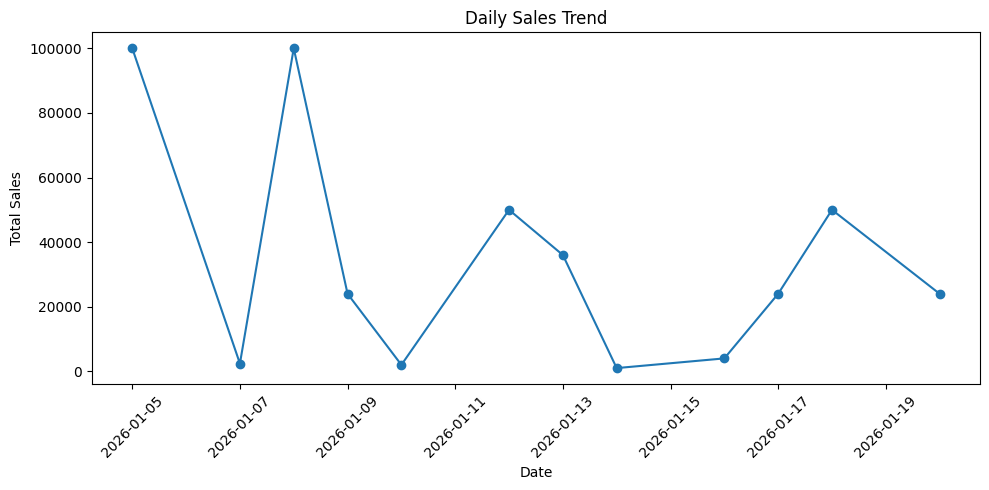

In [34]:
# Chart 2: Daily sales using Matplotlib
daily_sales = df.groupby('date')['total_sales'].sum()

plt.figure(figsize=(10, 5))

plt.plot(daily_sales.index, daily_sales.values, marker='o')

plt.title('Daily Sales Trend')
plt.xlabel('Date')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

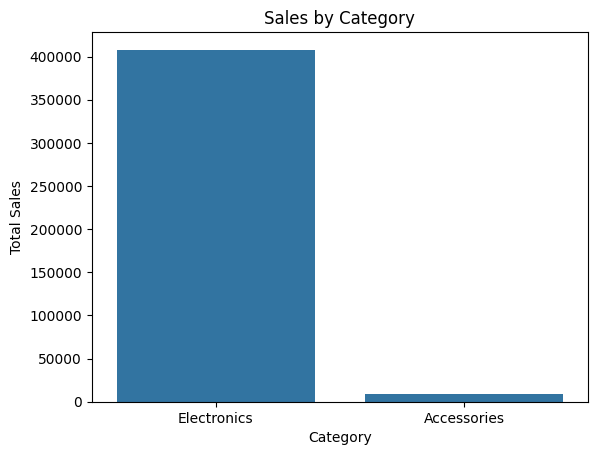

In [35]:
# Chart 3: Sales by category using Seaborn
sns.barplot(
    data=df,
    x='category',
    y='total_sales',
    estimator=sum,
    errorbar=None
)

plt.title('Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')

plt.show()

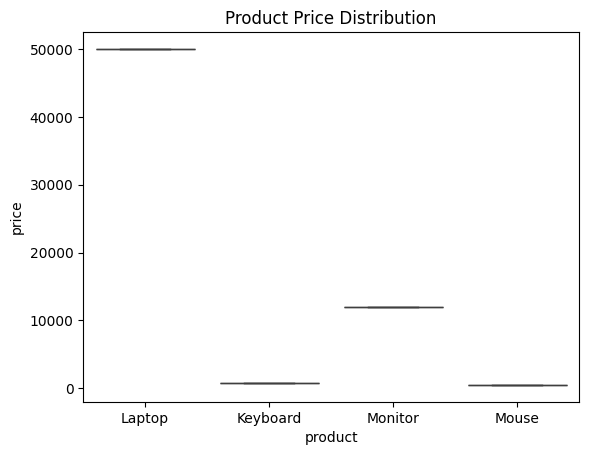

In [36]:
# Chart 4: Detect unusual prices using a box plot
sns.boxplot(
    data=df,
    x='product',
    y='price'
)

plt.title('Product Price Distribution')
plt.show()

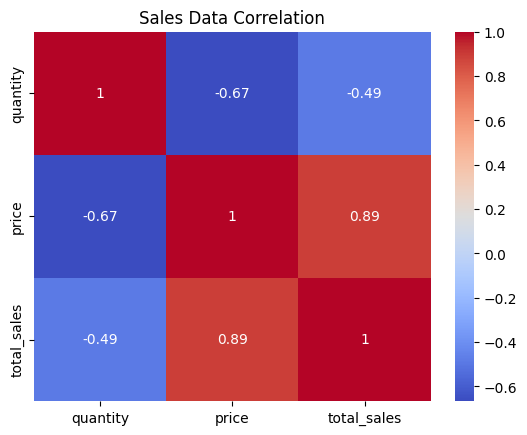

In [37]:
# Chart 5: Correlation heatmap
numeric_data = df[
    ['quantity', 'price', 'total_sales']
]

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Sales Data Correlation')
plt.show()